ER diagram created:


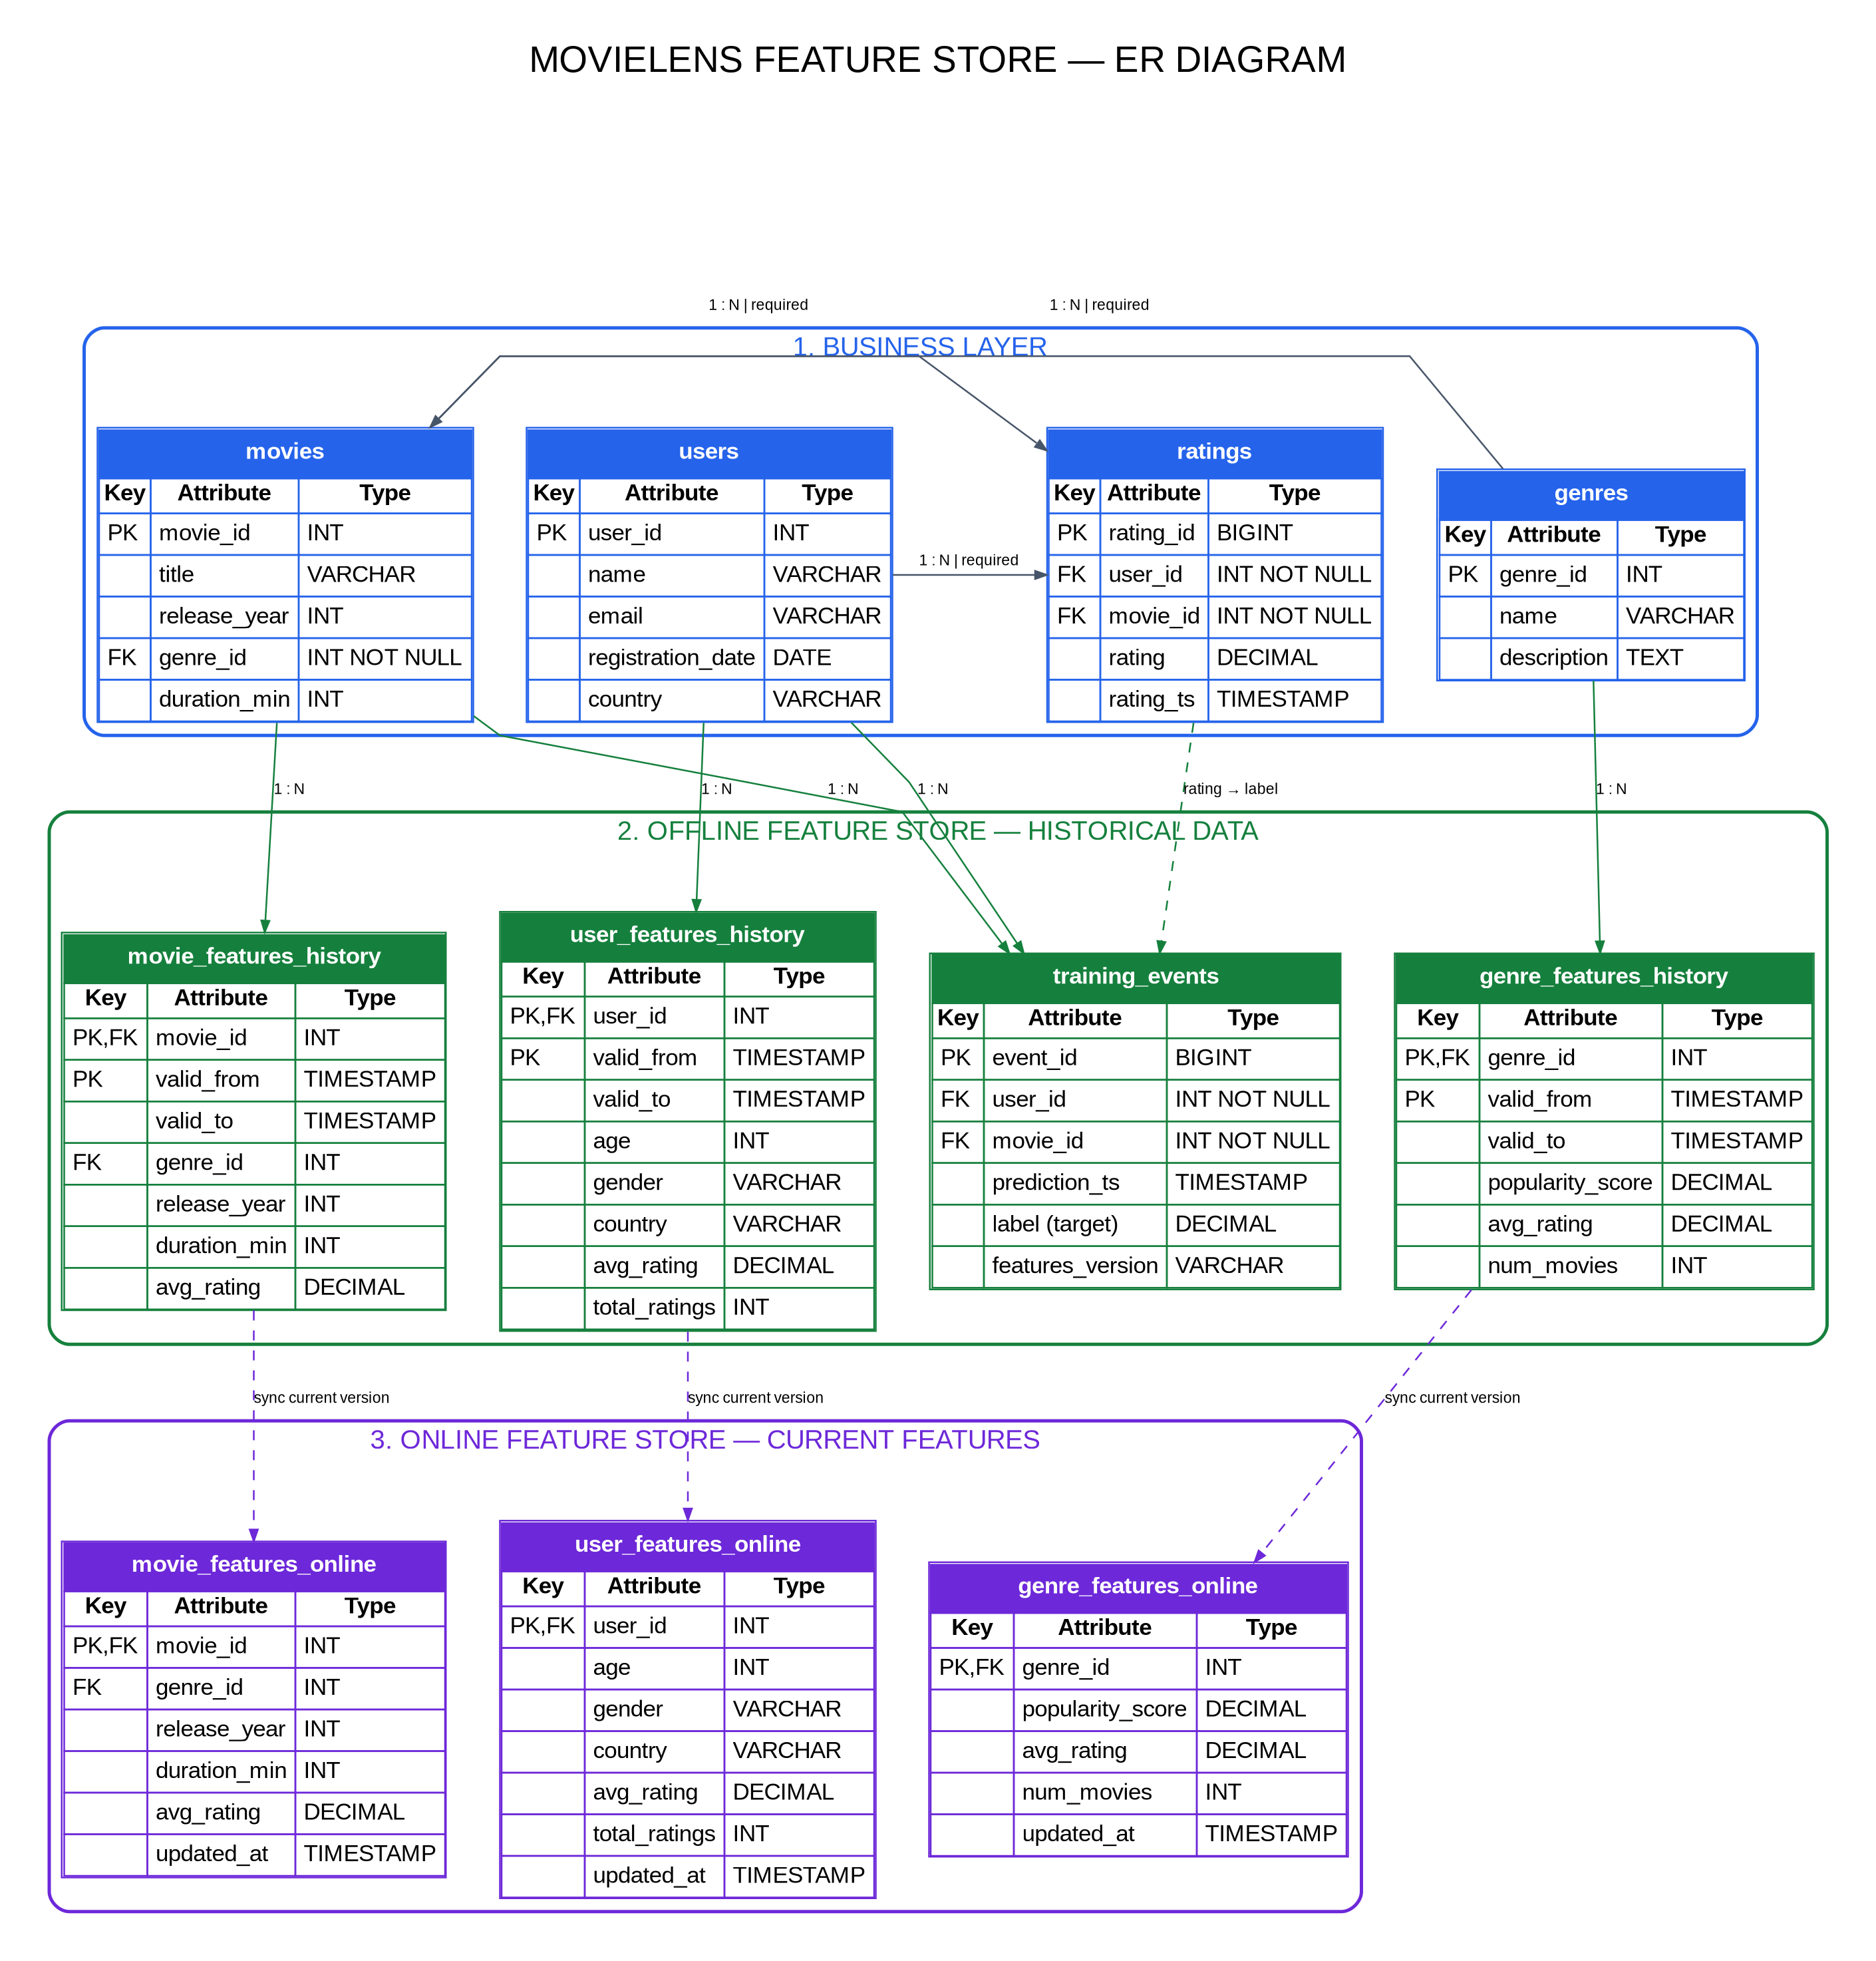

PNG: movielens_feature_store_ER.png
PDF: movielens_feature_store_ER.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!apt-get -qq install -y graphviz
!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display, Image
from google.colab import files
import pandas as pd
import subprocess
from io import StringIO

g = Digraph("MovieLens_ER", format="png", engine="dot")

g.attr(
    rankdir="TB",
    splines="polyline",
    nodesep="0.45",
    ranksep="1.0",
    pad="0.3",
    bgcolor="white",
    dpi="180",
    size="18,18",
    ratio="compress",
    labelloc="t",
    label="MOVIELENS FEATURE STORE — ER DIAGRAM",
    fontsize="22",
    fontname="Arial"
)
g.attr("node", shape="plain", fontname="Arial")
g.attr("edge", fontname="Arial", fontsize="9",
       arrowsize="0.7", color="#475569")

def make_table(title, fields, color):
    rows = ""
    for key, name, dtype in fields:
        rows += (
            '<TR>'
            f'<TD ALIGN="LEFT" CELLPADDING="4">{key}</TD>'
            f'<TD ALIGN="LEFT" CELLPADDING="4">{name}</TD>'
            f'<TD ALIGN="LEFT" CELLPADDING="4">{dtype}</TD>'
            '</TR>'
        )
    return (
        '<<TABLE BORDER="1" CELLBORDER="1" CELLSPACING="0" '
        f'COLOR="{color}" CELLPADDING="2">'
        f'<TR><TD COLSPAN="3" BGCOLOR="{color}" CELLPADDING="6">'
        f'<FONT COLOR="white"><B>{title}</B></FONT></TD></TR>'
        '<TR><TD><B>Key</B></TD><TD><B>Attribute</B></TD>'
        f'<TD><B>Type</B></TD></TR>{rows}</TABLE>>'
    )

BLUE = "#2563EB"
GREEN = "#15803D"
PURPLE = "#6D28D9"

def add_table(node_id, title, fields, color):
    g.node(node_id, label=make_table(title, fields, color))


with g.subgraph(name="cluster_business") as c:
    c.attr(label="1. BUSINESS LAYER",
           color=BLUE, style="rounded", penwidth="2",
           fontsize="16", fontcolor=BLUE)

    c.node("users", label=make_table("users", [
        ("PK", "user_id", "INT"),
        ("", "name", "VARCHAR"),
        ("", "email", "VARCHAR"),
        ("", "registration_date", "DATE"),
        ("", "country", "VARCHAR"),
    ], BLUE))

    c.node("movies", label=make_table("movies", [
        ("PK", "movie_id", "INT"),
        ("", "title", "VARCHAR"),
        ("", "release_year", "INT"),
        ("FK", "genre_id", "INT NOT NULL"),
        ("", "duration_min", "INT"),
    ], BLUE))

    c.node("genres", label=make_table("genres", [
        ("PK", "genre_id", "INT"),
        ("", "name", "VARCHAR"),
        ("", "description", "TEXT"),
    ], BLUE))

    c.node("ratings", label=make_table("ratings", [
        ("PK", "rating_id", "BIGINT"),
        ("FK", "user_id", "INT NOT NULL"),
        ("FK", "movie_id", "INT NOT NULL"),
        ("", "rating", "DECIMAL"),
        ("", "rating_ts", "TIMESTAMP"),
    ], BLUE))

    with c.subgraph() as s:
        s.attr(rank="same")
        s.node("users")
        s.node("ratings")
        s.node("movies")
        s.node("genres")


g.edge("users", "ratings",
       label="1 : N | required",
       constraint="false")
g.edge("movies", "ratings",
       label="1 : N | required",
       constraint="false")
g.edge("genres", "movies",
       label="1 : N | required",
       constraint="false")


with g.subgraph(name="cluster_offline") as c:
    c.attr(label="2. OFFLINE FEATURE STORE — HISTORICAL DATA",
           color=GREEN, style="rounded", penwidth="2",
           fontsize="16", fontcolor=GREEN)

    c.node("user_hist", label=make_table("user_features_history", [
        ("PK,FK", "user_id", "INT"),
        ("PK", "valid_from", "TIMESTAMP"),
        ("", "valid_to", "TIMESTAMP"),
        ("", "age", "INT"),
        ("", "gender", "VARCHAR"),
        ("", "country", "VARCHAR"),
        ("", "avg_rating", "DECIMAL"),
        ("", "total_ratings", "INT"),
    ], GREEN))

    c.node("movie_hist", label=make_table("movie_features_history", [
        ("PK,FK", "movie_id", "INT"),
        ("PK", "valid_from", "TIMESTAMP"),
        ("", "valid_to", "TIMESTAMP"),
        ("FK", "genre_id", "INT"),
        ("", "release_year", "INT"),
        ("", "duration_min", "INT"),
        ("", "avg_rating", "DECIMAL"),
    ], GREEN))

    c.node("genre_hist", label=make_table("genre_features_history", [
        ("PK,FK", "genre_id", "INT"),
        ("PK", "valid_from", "TIMESTAMP"),
        ("", "valid_to", "TIMESTAMP"),
        ("", "popularity_score", "DECIMAL"),
        ("", "avg_rating", "DECIMAL"),
        ("", "num_movies", "INT"),
    ], GREEN))

    c.node("events", label=make_table("training_events", [
        ("PK", "event_id", "BIGINT"),
        ("FK", "user_id", "INT NOT NULL"),
        ("FK", "movie_id", "INT NOT NULL"),
        ("", "prediction_ts", "TIMESTAMP"),
        ("", "label (target)", "DECIMAL"),
        ("", "features_version", "VARCHAR"),
    ], GREEN))

    with c.subgraph() as s:
        s.attr(rank="same")
        for n in ["user_hist", "movie_hist",
                  "genre_hist", "events"]:
            s.node(n)


g.edge("users", "user_hist",
       label="1 : N", color=GREEN)
g.edge("movies", "movie_hist",
       label="1 : N", color=GREEN)
g.edge("genres", "genre_hist",
       label="1 : N", color=GREEN)
g.edge("users", "events",
       label="1 : N", color=GREEN)
g.edge("movies", "events",
       label="1 : N", color=GREEN)
g.edge("ratings", "events",
       label="rating → label",
       style="dashed", color=GREEN)


with g.subgraph(name="cluster_online") as c:
    c.attr(label="3. ONLINE FEATURE STORE — CURRENT FEATURES",
           color=PURPLE, style="rounded", penwidth="2",
           fontsize="16", fontcolor=PURPLE)

    c.node("user_online", label=make_table("user_features_online", [
        ("PK,FK", "user_id", "INT"),
        ("", "age", "INT"),
        ("", "gender", "VARCHAR"),
        ("", "country", "VARCHAR"),
        ("", "avg_rating", "DECIMAL"),
        ("", "total_ratings", "INT"),
        ("", "updated_at", "TIMESTAMP"),
    ], PURPLE))

    c.node("movie_online", label=make_table("movie_features_online", [
        ("PK,FK", "movie_id", "INT"),
        ("FK", "genre_id", "INT"),
        ("", "release_year", "INT"),
        ("", "duration_min", "INT"),
        ("", "avg_rating", "DECIMAL"),
        ("", "updated_at", "TIMESTAMP"),
    ], PURPLE))

    c.node("genre_online", label=make_table("genre_features_online", [
        ("PK,FK", "genre_id", "INT"),
        ("", "popularity_score", "DECIMAL"),
        ("", "avg_rating", "DECIMAL"),
        ("", "num_movies", "INT"),
        ("", "updated_at", "TIMESTAMP"),
    ], PURPLE))

    with c.subgraph() as s:
        s.attr(rank="same")
        for n in ["user_online", "movie_online", "genre_online"]:
            s.node(n)


g.edge("user_hist", "user_online",
       label="sync current version",
       style="dashed", color=PURPLE)
g.edge("movie_hist", "movie_online",
       label="sync current version",
       style="dashed", color=PURPLE)
g.edge("genre_hist", "genre_online",
       label="sync current version",
       style="dashed", color=PURPLE)

png_file = g.render("movielens_feature_store_ER", cleanup=True)

g.format = "pdf"
pdf_file = g.render("movielens_feature_store_ER", cleanup=True)

print("ER diagram created:")
display(Image(filename=png_file, width=1200))

print("PNG:", png_file)
print("PDF:", pdf_file)

files.download(png_file)
